# Activity 1: Build a Blockchain
**Blockchain Wonders workshop · about 30 minutes**

You will build a working blockchain from nothing, break it, and see why it is hard to cheat.

| Step | What you do | Idea |
|---|---|---|
| 1 | Fingerprint some data | hashing |
| 2 | Make a block and link blocks | the chain |
| 3 | Tamper with history | tamper evidence |
| 4 | Sign records | digital identity |
| 5 | Mine | proof of work |
| 6 | Run a network | consensus |

Cells marked **Your turn** have a `TODO`. If you get stuck, ask, or open the notebook with the same name in the `solutions` folder.

In [5]:
# Setup: run this cell first.
import os, sys
import numpy, pandas, matplotlib          # loads the packages in JupyterLite
try:
    import sklearn
except ImportError:
    print("scikit-learn not found: agents will use the built-in rule tree instead.")

if not os.path.isdir("wonders"):
    if os.path.isdir("../wonders"):
        sys.path.insert(0, "..")
    else:
        try:                                # Google Colab: upload the workshop zip
            from google.colab import files
            import zipfile
            print("Upload blockchain_wonders.zip")
            name = next(iter(files.upload()))
            zipfile.ZipFile(name).extractall(".")
            sys.path.insert(0, "blockchain_wonders")
        except ImportError:
            print("Cannot find the 'wonders' folder. Keep this notebook next to it.")

import wonders
print("Ready. wonders version", wonders.__version__)

Ready. wonders version 1.0


## 1. Hashing: a fingerprint for data

A hash function turns any data into a short fixed-length code. Two properties matter:

- the **same** data always gives the **same** code
- a **tiny** change in the data gives a **completely different** code

In [10]:
from wonders import sha256_hex

print(sha256_hex("Pay Ali 100"))
print(sha256_hex("Pay Ali 100"))   # same data, same fingerprint
print(sha256_hex("Pay Ali 900"))   # one character changed

2799ea63602ad4a828a9703dbd797fd8a9d977b5993ca4ffa92f7627b224ce32
2799ea63602ad4a828a9703dbd797fd8a9d977b5993ca4ffa92f7627b224ce32
2546c8bebd18891e7a92d8c8b70742d848c03852aedfbcf7a0771124d9fa062c


**Your turn.** Hash your own name, then change one letter and hash it again.

In [11]:
# TODO: put your name in the first line and a one-letter change in the second
mine = sha256_hex("WorkSho")
changed = sha256_hex("Blockchain")
print(mine)
print(changed)
different = sum(a != b for a, b in zip(mine, changed))
print(f"{different} of 64 characters changed")

23682f45eb5d7373bdc6562a216a4bf52bf24221613b8e57b077c708fdeee82f
625da44e4eaf58d61cf048d168aa6f5e492dea166d8bb54ec06c30de07db57e1
59 of 64 characters changed


## 2. A block, and a chain of blocks

A block is a container of records. Its hash covers **everything** inside it, including the hash of the block before it. That backward reference is the chain.

**Your turn.** Finish `block_hash` so it returns the fingerprint of the whole block.

In [12]:
def make_block(index, records, previous_hash):
    block = {"index": index, "records": records, "previous_hash": previous_hash}
    block["hash"] = block_hash(block)
    return block

def block_hash(block):
    contents = {"index": block["index"],
                "records": block["records"],
                "previous_hash": block["previous_hash"]}
    return sha256_hex(contents)

genesis = make_block(0, ["Fund created with 1000"], "0" * 64)
block1  = make_block(1, ["Grant 100 to Ali"], genesis["hash"])
block2  = make_block(2, ["Grant 250 to Sara"], block1["hash"])
my_chain = [genesis, block1, block2]

for b in my_chain:
    print(b["index"], b["records"], "| prev", b["previous_hash"][:8], "| hash", b["hash"][:8])

TypeError: 'NoneType' object is not subscriptable

**Your turn.** Write the checker. A chain is healthy when, for every block:

1. its stored hash equals a freshly computed hash, and
2. its `previous_hash` equals the hash of the block before it.

In [14]:
def check_chain(chain):
    for i, block in enumerate(chain):
        # TODO: if the stored hash is not equal to block_hash(block), return a message
        pass
        # TODO: if i > 0 and previous_hash does not match the earlier block's hash, return a message
        pass
    return "Chain is healthy"

print(check_chain(my_chain))

Chain is healthy


## 3. Tamper with history

Sara would like 2,500 instead of 250. Change the record and run the checker.

In [15]:
my_chain[2]["records"] = ["Grant 2500 to Sara"]
print(check_chain(my_chain))

Chain is healthy


The cheat is caught because the block no longer matches its fingerprint. A clever cheat recalculates the hash too. Try it.

In [16]:
my_chain[2]["records"] = ["Grant 250 to Sara"]    # put block 2 back as it was
print("restored:", check_chain(my_chain))

my_chain[1]["records"] = ["Grant 900 to Ali"]
my_chain[1]["hash"] = block_hash(my_chain[1])     # cover the tracks
print(check_chain(my_chain))

restored: Chain is healthy
Chain is healthy


Now block 2 points to a hash that no longer exists. To hide one change, the cheat has to rewrite **every block after it**. Hold that thought for step 5.

## 4. Who wrote this record? Digital signatures

From here on we use the workshop library, which has the same ideas with more features.

Each participant has a **wallet**: a private key to sign with and a public key that anyone can use to check the signature.

In [17]:
from wonders import Wallet, make_transaction, verify_transaction

ali = Wallet("ali")
tx = make_transaction(ali, "grant_request", {"amount": 100, "purpose": "school books"})
print("signed by:", tx["sender"], "| address", tx["sender_address"])
print("signature valid?", verify_transaction(tx))

signed by: ali | address 2fdb695815d3
signature valid? True


**Your turn.** Change the amount inside `tx` and verify again. What happens, and why?

In [18]:
# TODO: change tx["payload"]["amount"] to 9000
...
print("signature valid?", verify_transaction(tx))

signature valid? True


## 5. A real chain, and mining

`Blockchain` refuses records with bad signatures and makes every block cost some computing work (**proof of work**): the block's hash must start with a number of zeros, found by trial and error.

Block #0 | 0 tx | prev 0000000000... | hash 00075dfc67...
Block #1 | 1 tx | prev 00075dfc67... | hash 0002f846fa...
Block #2 | 1 tx | prev 0002f846fa... | hash 000e03169b...
Block #3 | 1 tx | prev 000e03169b... | hash 000c850b4c...
problems found: []


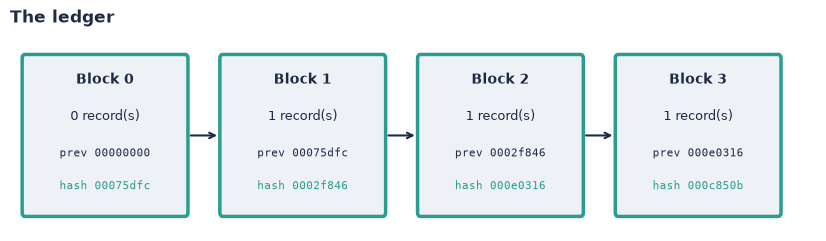

In [19]:
from wonders import Blockchain
from wonders.viz import draw_chain

ledger = Blockchain(difficulty=3)
sara = Wallet("sara")

ledger.record(ali,  "grant_request", {"amount": 100, "purpose": "school books"})
ledger.record(sara, "grant_request", {"amount": 250, "purpose": "sewing machine"})
ledger.record(ali,  "receipt",       {"amount": 100, "note": "books bought"})

print(ledger)
print("problems found:", ledger.audit())
draw_chain(ledger)

In [20]:
# The forged transaction from step 4 is refused
try:
    ledger.add_transaction(tx)
except ValueError as err:
    print(err)

**How expensive is mining?** Each extra zero multiplies the work. Run the experiment.

difficulty 1:       2 attempts -> 0bddc0951aa989d9...
difficulty 2:     211 attempts -> 008ca39e1af189c4...
difficulty 3:   12233 attempts -> 0004137aac08b7e0...
difficulty 4:   28021 attempts -> 0000f5cb03292ca4...


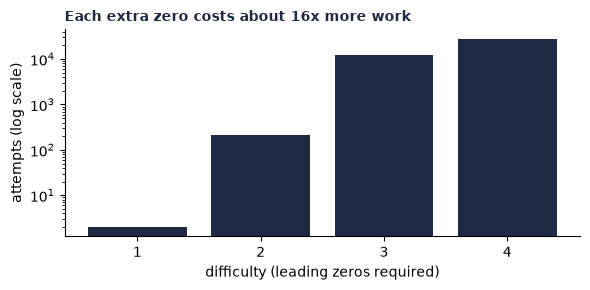

In [21]:
from wonders import Block
from wonders.viz import draw_mining

results = []
for difficulty in range(1, 5):
    block = Block(1, [{"demo": "data"}], "0" * 64)
    attempts = block.mine(difficulty)
    results.append((difficulty, attempts + 1))
    print(f"difficulty {difficulty}: {attempts + 1:>7} attempts -> {block.hash[:16]}...")
draw_mining(results)

**Your turn.** Tamper with the real ledger: change Sara's amount in block 2, then audit and draw the chain.

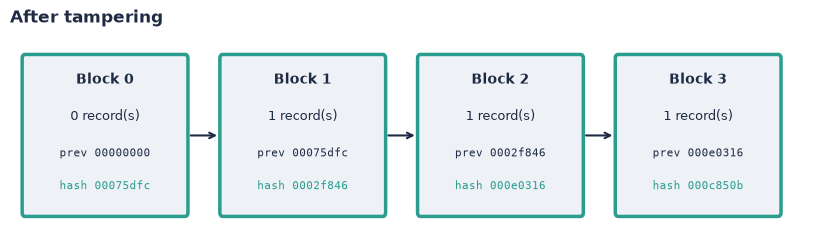

In [22]:
# TODO: set ledger.chain[2].transactions[0]["payload"]["amount"] to 2500
...
for problem in ledger.audit():
    print(problem)
draw_chain(ledger, title="After tampering")

The signature fails (Sara did not sign 2,500) and the block's hash fails. To hide it the cheat would need Sara's private key **and** would need to re-mine this block and every later one.

## 6. Consensus: no single copy is the truth

Five independent nodes each keep their own copy. One of them cheats.

In [ ]:
from wonders import Network

ledger = Blockchain(difficulty=3)
ledger.record(ali, "grant_request", {"amount": 100})
net = Network(["node-1", "node-2", "node-3", "node-4", "node-5"], ledger)

# a new block is announced; every node checks it for itself
block = ledger.record(sara, "grant_request", {"amount": 250})
print("accepted by:", net.broadcast(block))

# node-3 rewrites its own copy
net.nodes["node-3"].chain[1].transactions[0]["payload"]["amount"] = 99999

tip, agree, disagree = net.consensus()
print("majority agrees on", tip[:12], "->", agree)
print("out of step:", disagree)

**Your turn.** Repair the network, then check consensus again.

In [ ]:
# TODO: call net.repair() and print what it returns
...
tip, agree, disagree = net.consensus()
print("agree:", agree, "| out of step:", disagree)

## Discuss with your neighbour (3 minutes)

1. In step 3 the checker caught the cheat. Who has to run the checker for that to matter?
2. If three of five nodes cheat together, what does `consensus()` report? Try it.
3. Name one record in your own organisation that would benefit from being tamper-evident, and one that would not.

**Next:** Activity 2 puts AI agents on this ledger.